# Vehicle Counter Integrate with Database

## Install semua package yang dibutuhkan (ada di requirements.txt)

In [11]:
!pip install -r requirements.txt

## import all the packages

In [ ]:
import cv2
import os
import psycopg2
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from ultralytics import YOLO
model = YOLO("yolov8n.pt") 




## Load Video Source 

In [3]:
# load video source
video_path = 'https://dki-jkt.balitower.co.id:7028/502506_JKP_SATPOL-PP_JL.-GERBANG-PEMUDA-C04_CCTV-01/tracks-v1/index.fmp4.m3u8' 
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frame_display = cv2.resize(frame, (960, 540))
    
    cv2.imshow("CCTV Jakarta", frame_display)
    if cv2.waitKey(20) & 0xFF == ord('q'):
        break
cap.release()
cv2.destroyAllWindows()


## Connect to Database

In [35]:
load_dotenv(override=True)

try:
    conn = psycopg2.connect(
        host=os.getenv("DB_HOST"),
        database=os.getenv("DB_NAME"),  
        user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        port=os.getenv("DB_PORT")
    )
    cursor = conn.cursor()
    print(" Berhasil terhubung ke database PostgreSQL!")
    cursor.execute("""
        CREATE TABLE IF NOT EXISTS traffic_detection_logs (
            id SERIAL PRIMARY KEY,
            vehicle_type VARCHAR(50) NOT NULL,
            confidence_score REAL NOT NULL,
            timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
    """)
    conn.commit()
    print(" Tabel 'traffic_detection_logs' sudah siap!")
except Exception as e:
    print(f"Gagal koneksi ke PostgreSQL: {e}")
    exit()


 Berhasil terhubung ke database PostgreSQL!
 Tabel 'traffic_detection_logs' sudah siap!


## Object Detection (Mobil, Motor, Bus, Truk)

In [5]:
video_path = 'https://dki-jkt.balitower.co.id:7028/502506_JKP_SATPOL-PP_JL.-GERBANG-PEMUDA-C04_CCTV-01/tracks-v1/index.fmp4.m3u8'
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_BUFFERSIZE, 1)
class_map = {
    2: "Mobil",
    3: "Motor",
    5: "Bus",
    7: "Truk"
}
frame_count = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    frame_count += 1
    results = model(frame, classes=[3, 2, 5, 7], verbose=False) # 5 = bus, 2 = car, 3 = motorcycle, 7 = truck
    annotated_frame = results[0].plot()

    if frame_count % 30 == 0:
         for box in results[0].boxes:
            cls_id = int(box.cls[0])
            conf = round(float(box.conf[0]) * 100, 1)  
            vehicle_name = class_map.get(cls_id, "Lainnya")
            check_query = """
                SELECT id FROM traffic_detection_logs 
                WHERE vehicle_type = %s AND ROUND(confidence_score::numeric, 1) = %s
                ORDER BY id DESC LIMIT 1;
            """
            cursor.execute(check_query, (vehicle_name, conf))
            existing_row = cursor.fetchone()
            if existing_row:
                log_id = existing_row[0]
                update_query = """
                    UPDATE traffic_detection_logs 
                    SET timestamp = CURRENT_TIMESTAMP 
                    WHERE id = %s;
                """
                cursor.execute(update_query, (log_id,))
                print(f"[DB UPDATE] ID #{log_id} ({vehicle_name} {conf}%) waktunya diperbarui.")
            else:
                insert_query = """
                    INSERT INTO traffic_detection_logs (vehicle_type, confidence_score)
                    VALUES (%s, %s);
                """
                cursor.execute(insert_query, (vehicle_name, conf))
                print(f"[DB INSERT] {vehicle_name} ({conf}%) baru tercatat!")
    conn.commit()
    cv2.imshow("YOLOv8 + PostgreSQL Real-Time Monitoring", annotated_frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
if cursor:
    cursor.close()
    conn.close()
cap.release()
cv2.destroyAllWindows()
print("Koneksi database ditutup dan program selesai.")

[DB INSERT] Mobil (90.4%) baru tercatat!
[DB INSERT] Mobil (61.4%) baru tercatat!
[DB INSERT] Mobil (60.7%) baru tercatat!
[DB INSERT] Mobil (54.1%) baru tercatat!
[DB INSERT] Mobil (38.9%) baru tercatat!
[DB INSERT] Bus (32.8%) baru tercatat!
[DB INSERT] Mobil (85.9%) baru tercatat!
[DB INSERT] Mobil (77.0%) baru tercatat!
[DB INSERT] Mobil (74.9%) baru tercatat!
[DB INSERT] Mobil (64.5%) baru tercatat!
[DB INSERT] Mobil (28.8%) baru tercatat!
[DB INSERT] Mobil (81.8%) baru tercatat!
[DB INSERT] Mobil (79.8%) baru tercatat!
[DB INSERT] Mobil (68.4%) baru tercatat!
[DB INSERT] Mobil (51.2%) baru tercatat!
[DB INSERT] Bus (39.1%) baru tercatat!
[DB INSERT] Mobil (35.5%) baru tercatat!
[DB INSERT] Mobil (32.7%) baru tercatat!
[DB INSERT] Mobil (31.9%) baru tercatat!
[DB INSERT] Mobil (25.3%) baru tercatat!
[DB INSERT] Mobil (75.2%) baru tercatat!
[DB INSERT] Mobil (74.3%) baru tercatat!
[DB INSERT] Mobil (73.5%) baru tercatat!
[DB INSERT] Mobil (69.9%) baru tercatat!
[DB INSERT] Mobil (3

## Data visualization

### Tarik Data dari Database

In [ ]:
query = "SELECT vehicle_type, confidence_score, timestamp FROM traffic_detection_logs;"
df = pd.read_sql(query, conn)
conn.close()
if df.empty:
    print("Database masih kosong")
else:
    df["timestamp"] = pd.to_datetime(df["timestamp"])


### Layout Dashboard Grafik (2x2) 

C:\Users\Evan\AppData\Local\Temp\ipykernel_18008\3689319348.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=axes[0, 1], palette="Blues_d")


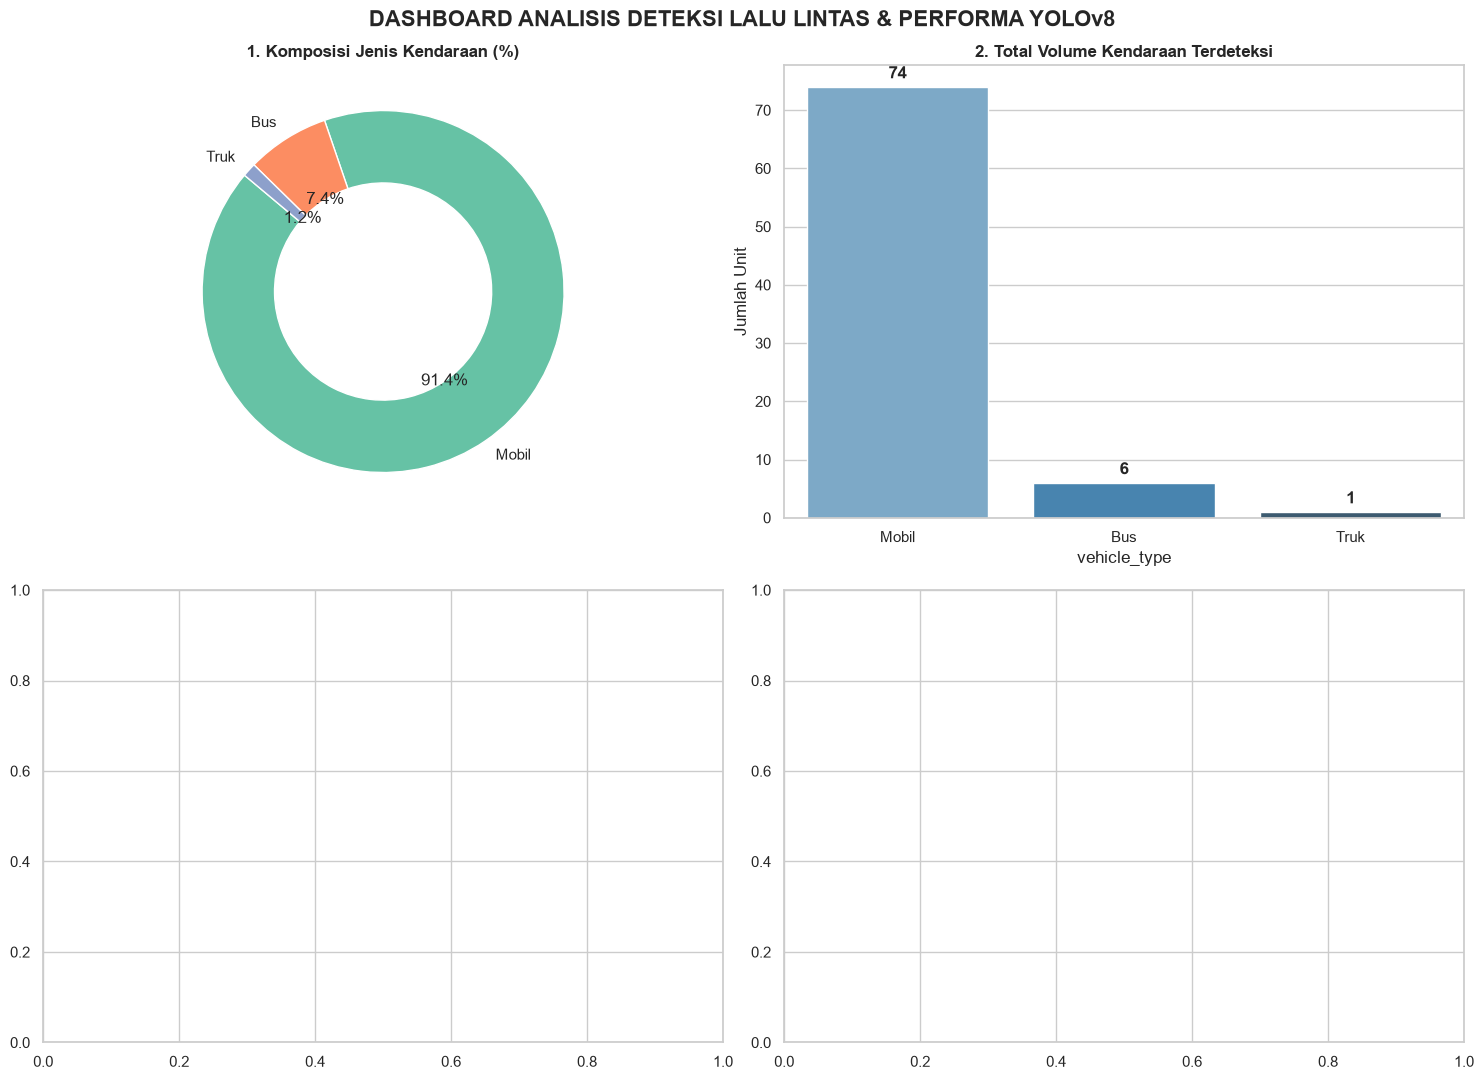

In [ ]:
%matplotlib inline

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle("DASHBOARD ANALISIS DETEKSI LALU LINTAS & PERFORMA YOLOv8", fontsize=16, weight="bold")
counts = df["vehicle_type"].value_counts()
palette_custom = sns.color_palette("Set2", len(counts))
# GRAFIK 1: PROPORSI KENDARAAN (DONUT CHART) 
axes[0, 0].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140,
                colors=palette_custom, wedgeprops=dict(width=0.4, edgecolor='w'))
axes[0, 0].set_title("1. Komposisi Jenis Kendaraan (%)", fontsize=12, weight="bold")

# GRAFIK 2: TOTAL UNIT KENDARAAN (BAR CHART)
sns.barplot(x=counts.index, y=counts.values, ax=axes[0, 1], palette="Blues_d")
axes[0, 1].set_title("2. Total Volume Kendaraan Terdeteksi", fontsize=12, weight="bold")
axes[0, 1].set_ylabel("Jumlah Unit")
for i, v in enumerate(counts.values):
    axes[0, 1].text(i, v + (max(counts.values) * 0.02), str(v), ha="center", weight="bold")

# GRAFIK 3: RATA-RATA AKURASI DETEKSI (BAR CHART) 
avg_conf = df.groupby("vehicle_type")["confidence_score"].mean().reindex(counts.index).reset_index()
sns.barplot(data=avg_conf, x="vehicle_type", y="confidence_score", ax=axes[1, 0], palette="Greens_d")
axes[1, 0].set_title("3. Rata-rata Akurasi Deteksi YOLOv8 (%)", fontsize=12, weight="bold")
axes[1, 0].set_ylabel("Akurasi (%)")
axes[1, 0].set_ylim(0, 105)
for i, row in avg_conf.iterrows():
    axes[1, 0].text(i, row["confidence_score"] + 2, f"{row['confidence_score']:.1f}%", ha="center", weight="bold")
    

plt.tight_layout()
plt.show()

C:\Users\Evan\AppData\Local\Temp\ipykernel_18008\1000354314.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)
C:\Users\Evan\AppData\Local\Temp\ipykernel_18008\1000354314.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=axes[0, 1], palette="Blues_d")
C:\Users\Evan\AppData\Local\Temp\ipykernel_18008\1000354314.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_conf, x="vehicle_type", y="confidence_score", ax=axes[1, 0], palette="Greens_d")


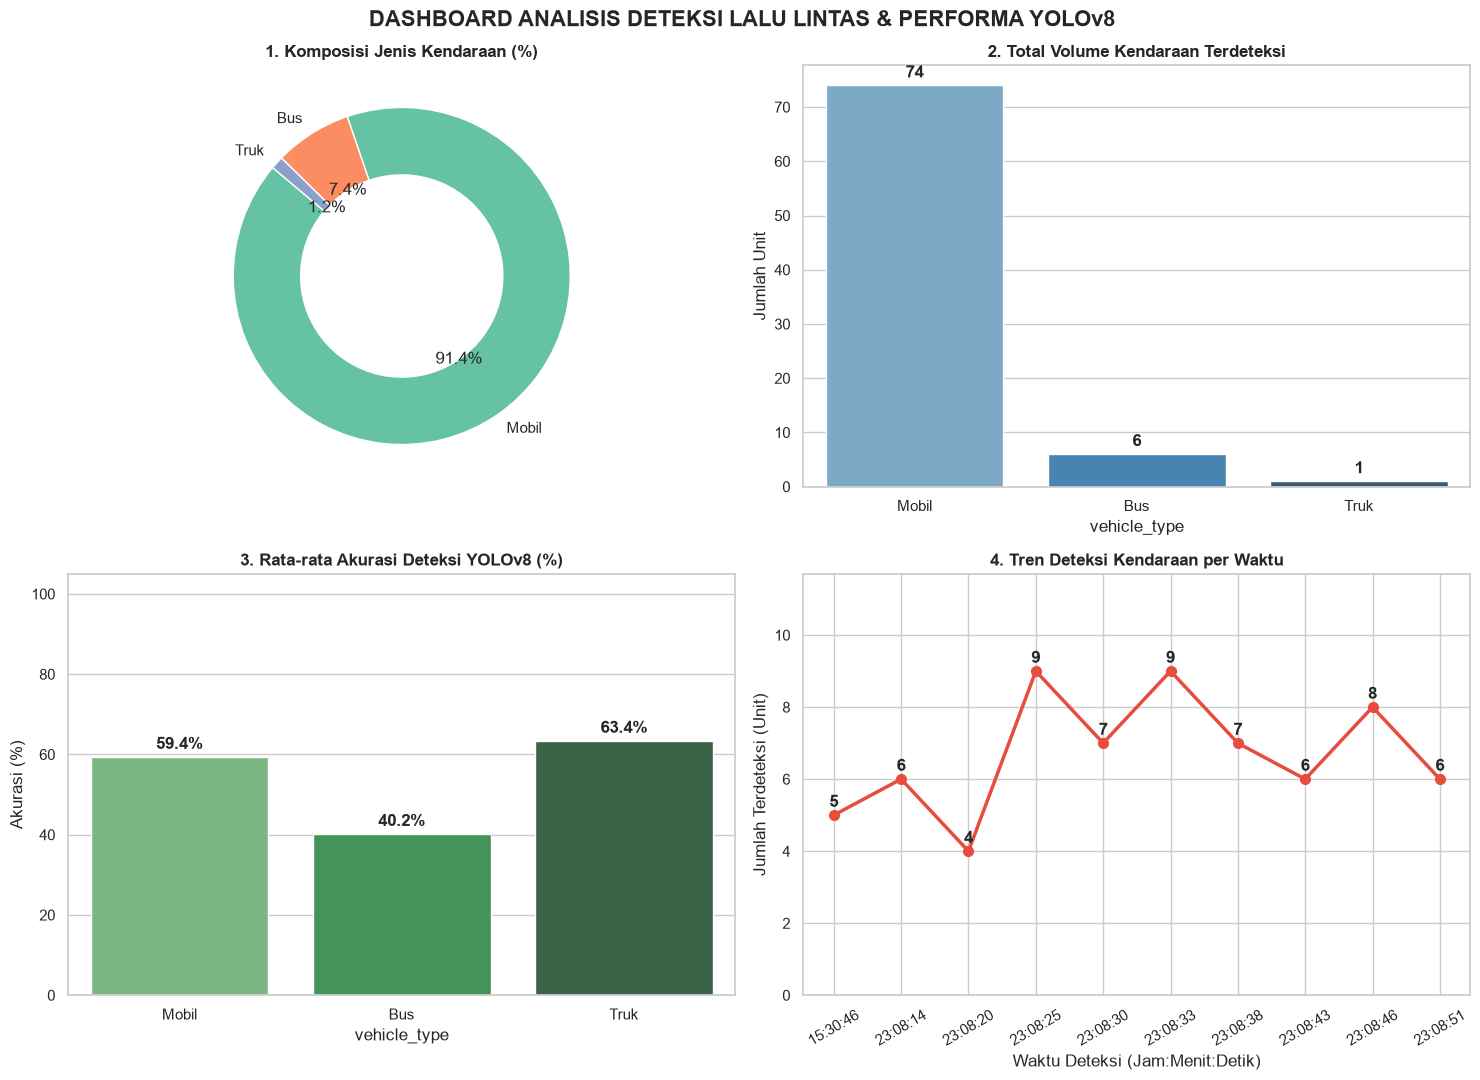

In [ ]:

    # GRAFIK 3: RATA-RATA AKURASI DETEKSI (BAR CHART) 
    avg_conf = df.groupby("vehicle_type")["confidence_score"].mean().reindex(counts.index).reset_index()
    sns.barplot(data=avg_conf, x="vehicle_type", y="confidence_score", ax=axes[1, 0], palette="Greens_d")
    axes[1, 0].set_title("3. Rata-rata Akurasi Deteksi YOLOv8 (%)", fontsize=12, weight="bold")
    axes[1, 0].set_ylabel("Akurasi (%)")
    axes[1, 0].set_ylim(0, 105)
    for i, row in avg_conf.iterrows():
        axes[1, 0].text(i, row["confidence_score"] + 2, f"{row['confidence_score']:.1f}%", ha="center", weight="bold")
    
    # GRAFIK 4: TREN KEPADATAN PER WAKTU (LINE CHART)
    df["waktu_detik"] = df["timestamp"].dt.strftime('%H:%M:%S')
    time_trend = df["waktu_detik"].value_counts().sort_index().tail(10)
    if len(time_trend) > 1:
        # Jika ada lebih dari 1 titik, gambar garis
        axes[1, 1].plot(time_trend.index, time_trend.values, 
                        marker='o', color="#e74c3c", linewidth=2.5, markersize=7)
    else:
        sns.barplot(x=time_trend.index, y=time_trend.values, ax=axes[1, 1], color="#e74c3c")
    axes[1, 1].set_title("4. Tren Deteksi Kendaraan per Waktu", fontsize=12, weight="bold")
    axes[1, 1].set_xlabel("Waktu Deteksi (Jam:Menit:Detik)")
    axes[1, 1].set_ylabel("Jumlah Terdeteksi (Unit)")
    # 3. Beri angka di atas titik/batang
    for i, (waktu, total) in enumerate(time_trend.items()):
        axes[1, 1].annotate(str(total), (i, total), 
                            textcoords="offset points", xytext=(0, 6), 
                            ha='center', weight='bold')
    axes[1, 1].set_ylim(0, max(time_trend.values) * 1.3)
    axes[1, 1].tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.show()